In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
from pathlib import Path
import re

from random import randint

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)
    
DATADIR = "../../Data/UMAP_embedding_ode"

rcParams.update({'figure.autolayout': True})

In [3]:
filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.match(r'embedding_erl', f)]
filenames_erl = [Path(DATADIR, f) for f in filenames]
filenames_erl.sort()

ode_divs_erl = np.genfromtxt(Path(DATADIR+'/erl_ode_divs.csv'), delimiter=',')
ode_max = max(ode_divs_erl)
# filenames_erl

In [4]:
filenames = [f for f in filepaths if re.match(r'embedding_dmso', f)]
filenames_dmso = [Path(DATADIR, f) for f in filenames]
filenames_dmso.sort()

ode_divs_dmso = np.genfromtxt(Path(DATADIR+'/dmso_ode_divs.csv'), delimiter=',')
ode_min = min(ode_divs_erl)
# filenames_dmso

In [5]:
size = (7,4)
xmin = 0
xmax = 16
ymin = -2
ymax = 16
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

C:\Users\Austin\AppData\Local\Temp\ipykernel_27604\2418442564.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')
C:\Users\Austin\anaconda3\envs\stoch_cell\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


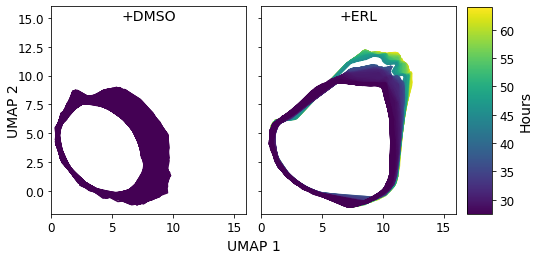

In [12]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_erl:
    embedding_tmp = pd.read_csv(f,header=None)    
    axes[1].plot(embedding_tmp.iloc[900:,0], embedding_tmp.iloc[900:,1], color=cm(norm(ode_divs_erl[ii])))
    ii+=1

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticklabels([])
    
ii=0
for f in filenames_dmso:
    embedding_tmp = pd.read_csv(f,header=None)    
    im = axes[0].plot(embedding_tmp.iloc[900:,0], embedding_tmp.iloc[900:,1], color=cm(norm(ode_divs_dmso[ii])))
    ii+=1
    
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')

fig.subplots_adjust(right=1)
cbar_ax = fig.add_axes([1, 0.24, 0.05, 0.72])
fig.colorbar(sm, cax=cbar_ax, label='Hours')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=25)
ax.set_ylabel('UMAP 2', labelpad=30)

fig4a_fn = Path(SAVEDIR, 'fig4a.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [17]:
size = (2,2)
xmin = 0
xmax = 14
ymin = -2
ymax = 16
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

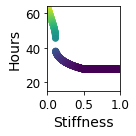

In [18]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

plt.scatter(x_lin, ode_divs_erl, color=cm(norm(ode_divs_erl)))
plt.xlim([0, 1])
plt.ylim([15, ode_max])
plt.xlabel('Stiffness')
plt.ylabel('Hours')

fig4a_fn = Path(SAVEDIR, 'fig4a_inset02.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()

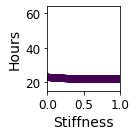

In [19]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

plt.scatter(x_lin, ode_divs_dmso, color=cm(norm(ode_divs_dmso)))
plt.xlim([0, 1])
plt.ylim([15, ode_max])
plt.xlabel('Stiffness')
plt.ylabel('Hours')

fig4a_fn = Path(SAVEDIR, 'fig4a_inset55.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()

In [20]:
lyap_erl = pd.read_csv(Path(DATADIR+'/lyap_avg_0402.txt'),header=None)
lyap_dmso = pd.read_csv(Path(DATADIR+'/lyap_avg_dmso.txt'),header=None)
lyap_sum = pd.read_csv(Path(DATADIR+'/lyap_sum.txt'),header=None)
x_lin = np.arange(0,1,0.01)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.04136,-0.048568,-0.0459,-0.042825,-0.050461,-0.05301,-0.056804,-0.063553,-0.058667,-0.047035,...,-0.046495,-0.046783,-0.046434,-0.045941,-0.04638,-0.047972,-0.047182,-0.04611,-0.051876,-0.047787


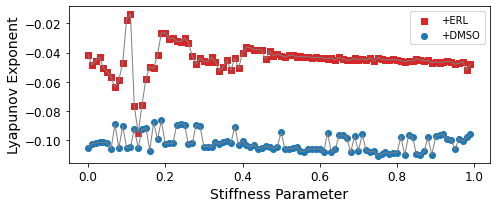

In [26]:
win = 21
pol = 2
size = (7,3)
xmin = 0
xmax = 1
ymin = -.12
ymax = 0

fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

norm = plt.Normalize(min(lyap_dmso.iloc[0,:]), max(lyap_erl.iloc[0,:]))
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

plt.scatter(x_lin, lyap_erl.iloc[0,:], color='tab:red', label='+ERL', marker='s')
plt.plot(x_lin, lyap_erl.iloc[0,:], color='gray', linewidth=1)
plt.scatter(x_lin, lyap_dmso.iloc[0,:], color='tab:blue', label='+DMSO')
plt.plot(x_lin, lyap_dmso.iloc[0,:], color='gray', linewidth=1)
plt.xlabel('Stiffness Parameter')
plt.ylabel('Lyapunov Exponent')
plt.legend()

fig4b = Path(SAVEDIR, 'fig4b.svg')

if SAVEFILES and (OVERWRITE or not fig4b.exists()):
    plt.savefig(fig4b, bbox_inches='tight')
else:
    plt.figure()